## Just some basic EDA and a how-to guide. ##

In [2]:
import re
import os
from pathlib import Path
import kagglehub

# Download latest version

# "magic" command to make plots show up in the notebook
%matplotlib inline 
filepath = Path(kagglehub.dataset_download("wordsforthewise/lending-club"))

print("Path to dataset files:", filepath)

/home/vlitoux/Projects/XAI_repo/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /home/vlitoux/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3


In [1]:
filepath

NameError: name 'filepath' is not defined

In [2]:
accepted_fn = filepath / 'accepted_2007_to_2018q4.csv' / 'accepted_2007_to_2018Q4.csv'

rejected_fn =  filepath / 'rejected_2007_to_2018q4.csv' / 'rejected_2007_to_2018Q4.csv'

accepted_fn.exists(), rejected_fn.exists()

(True, True)

In [3]:
try:
    import cudf as pd
    BACKEND = "cudf (GPU)"
    IS_GPU=True
except Exception:  # ImportError, or CUDA/driver errors on GPU-less machines
    import pandas as pd
    IS_GPU=False
    BACKEND = "pandas (CPU)"

print(f"Using {BACKEND}")


acc_df = pd.read_csv(accepted_fn)
# Takes a while to read, because these files are large...give it a minute or so
# acc_df = pd.read_csv(accepted_fn)

# this is a dataset with rejected loans from lendingclub

acc_df

Using cudf (GPU)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,<NA>,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,<NA>,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,<NA>,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,<NA>,35000.0,35000.0,35000.0,60 months,14.85,829.9,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,<NA>,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2260696,88985880,<NA>,40000.0,40000.0,40000.0,60 months,10.49,859.56,B,B3,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260697,88224441,<NA>,24000.0,24000.0,24000.0,60 months,14.49,564.56,C,C4,...,NaN,NaN,Cash,Y,Mar-2019,ACTIVE,Mar-2019,10000.0,44.82,1.0
2260698,88215728,<NA>,14000.0,14000.0,14000.0,60 months,14.49,329.33,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260699,Total amount funded in policy code 1: 1465324575,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
rej_df = pd.read_csv(rejected_fn)
rej_df

,Amount Requested,Application Date,Loan Title,Risk_Score,Debt-To-Income Ratio,Zip Code,State,Employment Length,Policy Code
0,1000.0,2007-05-26,Wedding Covered but No Honeymoon,693.0,10%,481xx,NM,4 years,0.0
1,1000.0,2007-05-26,Consolidating Debt,703.0,10%,010xx,MA,< 1 year,0.0
2,11000.0,2007-05-27,Want to consolidate my debt,715.0,10%,212xx,MD,1 year,0.0
3,6000.0,2007-05-27,waksman,698.0,38.64%,017xx,MA,< 1 year,0.0
4,1500.0,2007-05-27,mdrigo,509.0,9.43%,209xx,MD,< 1 year,0.0
...,...,...,...,...,...,...,...,...,...
27648736,10000.0,2016-12-31,Debt consolidation,590.0,41.26%,441xx,OH,< 1 year,0.0
27648737,10000.0,2016-12-31,moving,NaN,1.48%,207xx,MD,5 years,0.0
27648738,1200.0,2016-12-31,Other,686.0,10.26%,914xx,CA,< 1 year,0.0
27648739,25000.0,2016-12-31,debt_consolidation,NaN,17.71%,880xx,NM,< 1 year,0.0


In [12]:
rej_df["Loan Title"]

0           Wedding Covered but No Honeymoon
1                         Consolidating Debt
2                Want to consolidate my debt
3                                    waksman
4                                     mdrigo
                          ...               
27648736                  Debt consolidation
27648737                              moving
27648738                               Other
27648739                  debt_consolidation
27648740                            Business
Name: Loan Title, Length: 27648741, dtype: str

In [23]:
REJECTED_CONVERT_COLUMNS = {
    "Amount Requested": "loan_amnt",        # requested amount
    "Application Date": "issue_d",          # loan issue month
    "Loan Title": "title",                  # free-text title (not the category "purpose")
    "Risk_Score": "fico_range_low",         # accepted loans store a FICO range (low/high); pick one bound
    "Debt-To-Income Ratio": "dti",
    "Zip Code": "zip_code",
    "State": "addr_state",
    "Employment Length": "emp_length_str",
    "Policy Code": "policy_code",
    "debt_income_ratio": "dti",             # derived duplicate of Debt-To-Income Ratio
    "employment_lenght_years": "emp_length",  # numeric version of Employment Length
}
rej_df = rej_df.rename(columns=REJECTED_CONVERT_COLUMNS)
rej_df


,loan_amnt,issue_d,title,fico_range_low,dti,zip_code,addr_state,emp_length_str,policy_code
0,1000.0,2007-05-26,Wedding Covered but No Honeymoon,693.0,10%,481xx,NM,4 years,0.0
1,1000.0,2007-05-26,Consolidating Debt,703.0,10%,010xx,MA,< 1 year,0.0
2,11000.0,2007-05-27,Want to consolidate my debt,715.0,10%,212xx,MD,1 year,0.0
3,6000.0,2007-05-27,waksman,698.0,38.64%,017xx,MA,< 1 year,0.0
4,1500.0,2007-05-27,mdrigo,509.0,9.43%,209xx,MD,< 1 year,0.0
...,...,...,...,...,...,...,...,...,...
27648736,10000.0,2016-12-31,Debt consolidation,590.0,41.26%,441xx,OH,< 1 year,0.0
27648737,10000.0,2016-12-31,moving,NaN,1.48%,207xx,MD,5 years,0.0
27648738,1200.0,2016-12-31,Other,686.0,10.26%,914xx,CA,< 1 year,0.0
27648739,25000.0,2016-12-31,debt_consolidation,NaN,17.71%,880xx,NM,< 1 year,0.0


In [24]:
def percent_to_float(col: pd.Series):
    return col.str.removesuffix("%").astype("float64")
rej_df["dti"] = percent_to_float(rej_df["dti"])
rej_df

,loan_amnt,issue_d,title,fico_range_low,dti,zip_code,addr_state,emp_length_str,policy_code
0,1000.0,2007-05-26,Wedding Covered but No Honeymoon,693.0,10.00,481xx,NM,4 years,0.0
1,1000.0,2007-05-26,Consolidating Debt,703.0,10.00,010xx,MA,< 1 year,0.0
2,11000.0,2007-05-27,Want to consolidate my debt,715.0,10.00,212xx,MD,1 year,0.0
3,6000.0,2007-05-27,waksman,698.0,38.64,017xx,MA,< 1 year,0.0
4,1500.0,2007-05-27,mdrigo,509.0,9.43,209xx,MD,< 1 year,0.0
...,...,...,...,...,...,...,...,...,...
27648736,10000.0,2016-12-31,Debt consolidation,590.0,41.26,441xx,OH,< 1 year,0.0
27648737,10000.0,2016-12-31,moving,NaN,1.48,207xx,MD,5 years,0.0
27648738,1200.0,2016-12-31,Other,686.0,10.26,914xx,CA,< 1 year,0.0
27648739,25000.0,2016-12-31,debt_consolidation,NaN,17.71,880xx,NM,< 1 year,0.0


In [25]:

EMPLOYMENT_LENGTH_TO_YEARS = {
    "< 1 year": 1,
    "1 year": 2,
    "2 years": 3,
    "3 years": 4,
    "4 years": 5,
    "5 years": 6,
    "6 years": 7,
    "7 years": 8,
    "8 years": 9,
    "9 years": 10,
    "10+ years": 11,
}

def employment_length_to_years(employment_length: pd.Series) -> pd.Series:
    """Convert an 'Employment Length' column to numeric years.

    '< 1 year' -> 1, 'N years' -> N, '10+ years' -> 11.
    NaN (and any unknown value) stays null.
    """
    return employment_length.map(EMPLOYMENT_LENGTH_TO_YEARS)
rej_df["emp_length"] = employment_length_to_years(rej_df["emp_length_str"])
rej_df

,loan_amnt,issue_d,title,fico_range_low,dti,zip_code,addr_state,emp_length_str,policy_code,emp_length
0,1000.0,2007-05-26,Wedding Covered but No Honeymoon,693.0,10.00,481xx,NM,4 years,0.0,5.0
1,1000.0,2007-05-26,Consolidating Debt,703.0,10.00,010xx,MA,< 1 year,0.0,1.0
2,11000.0,2007-05-27,Want to consolidate my debt,715.0,10.00,212xx,MD,1 year,0.0,2.0
3,6000.0,2007-05-27,waksman,698.0,38.64,017xx,MA,< 1 year,0.0,1.0
4,1500.0,2007-05-27,mdrigo,509.0,9.43,209xx,MD,< 1 year,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
27648736,10000.0,2016-12-31,Debt consolidation,590.0,41.26,441xx,OH,< 1 year,0.0,1.0
27648737,10000.0,2016-12-31,moving,NaN,1.48,207xx,MD,5 years,0.0,6.0
27648738,1200.0,2016-12-31,Other,686.0,10.26,914xx,CA,< 1 year,0.0,1.0
27648739,25000.0,2016-12-31,debt_consolidation,NaN,17.71,880xx,NM,< 1 year,0.0,1.0


In [26]:
rej_df.dtypes

loan_amnt         float64
issue_d               str
title                 str
fico_range_low    float64
dti               float64
zip_code              str
addr_state            str
emp_length_str        str
policy_code       float64
emp_length        float64
dtype: object

In [27]:
rej_df.describe()

,loan_amnt,fico_range_low,dti,policy_code,emp_length
count,2.764874e+07,9.151111e+06,2.764874e+07,2.764782e+07,2.669739e+07
mean,1.313324e+04,6.281721e+02,1.433401e+02,6.375113e-03,1.712604e+00
std,1.500964e+04,8.993679e+01,1.053916e+04,1.127368e-01,1.965022e+00
min,0.000000e+00,0.000000e+00,-1.000000e+00,0.000000e+00,1.000000e+00
25%,4.800000e+03,5.910000e+02,8.060000e+00,0.000000e+00,1.000000e+00
50%,1.000000e+04,6.370000e+02,1.998000e+01,0.000000e+00,1.000000e+00
75%,2.000000e+04,6.750000e+02,3.661000e+01,0.000000e+00,1.000000e+00
max,1.400000e+06,9.900000e+02,5.000003e+07,2.000000e+00,1.100000e+01


In [29]:
import plotly.express as px

def show_correlation_matrix(df: pd.DataFrame, method: str = "pearson") -> pd.DataFrame:
    """Compute and display the correlation matrix between the numeric variables of a cuDF DataFrame."""
    numeric_df : pd.DataFrame = df.select_dtypes(include="number")
    corr = numeric_df.corr(method=method)  # computed on GPU, returns a cuDF DataFrame

    fig = px.imshow(
        corr.to_pandas(),                      # plotly needs host data
        text_auto=".2f",                       # annotate each cell
        zmin=-1, zmax=1,
        color_continuous_scale="RdBu_r",       # red = positive, blue = negative
        title=f"{method.capitalize()} correlation matrix",
        aspect="auto",
    )
    fig.update_layout(coloraxis_colorbar=dict(title="corr"))
    fig.show()

    return corr

show_correlation_matrix(rej_df.dropna())

,loan_amnt,fico_range_low,dti,policy_code,emp_length
loan_amnt,1.000000,0.244976,0.001229,0.008700,0.064590
fico_range_low,0.244976,1.000000,-0.001734,0.036847,0.127752
dti,0.001229,-0.001734,1.000000,-0.000281,-0.001913
policy_code,0.008700,0.036847,-0.000281,1.000000,0.110871
emp_length,0.064590,0.127752,-0.001913,0.110871,1.000000


Policy code is always 0 or 2 for rejected

In [30]:
acc_df_compare_rej = acc_df.copy()
acc_df_compare_rej["emp_length"] = employment_length_to_years(acc_df["emp_length"]) # convert years to int, equal to the number of years
acc_df_compare_rej

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,<NA>,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,<NA>,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,<NA>,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,<NA>,35000.0,35000.0,35000.0,60 months,14.85,829.9,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,<NA>,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2260696,88985880,<NA>,40000.0,40000.0,40000.0,60 months,10.49,859.56,B,B3,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260697,88224441,<NA>,24000.0,24000.0,24000.0,60 months,14.49,564.56,C,C4,...,NaN,NaN,Cash,Y,Mar-2019,ACTIVE,Mar-2019,10000.0,44.82,1.0
2260698,88215728,<NA>,14000.0,14000.0,14000.0,60 months,14.49,329.33,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260699,Total amount funded in policy code 1: 1465324575,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
show_correlation_matrix(acc_df_compare_rej[["loan_amnt", "fico_range_low", "dti", "emp_length", "policy_code"]].dropna())

,loan_amnt,fico_range_low,dti,emp_length,policy_code
loan_amnt,1.0,0.112711089,0.049126563,0.079238025,NaN
fico_range_low,0.112711089,1.0,-0.034479535,0.020770066,NaN
dti,0.049126563,-0.034479535,1.0,0.018087737,NaN
emp_length,0.079238025,0.020770066,0.018087737,1.0,NaN
policy_code,NaN,NaN,NaN,NaN,NaN


Policy code here is always equal to 1 when accepted

In [32]:
# Columns used for PCA and correlations
STUDIES_COLUMS = ["loan_amnt", "fico_range_low", "dti", "emp_length"] 
IS_ACCEPTED_COLUMN_NAME = "is_accepted"

rej_df[IS_ACCEPTED_COLUMN_NAME] = 0
acc_df_compare_rej[IS_ACCEPTED_COLUMN_NAME] = 1

In [34]:
all_df = pd.concat((rej_df[[IS_ACCEPTED_COLUMN_NAME] + STUDIES_COLUMS],acc_df_compare_rej[[IS_ACCEPTED_COLUMN_NAME] + ["loan_status"] + STUDIES_COLUMS]))
all_df["loan_status"] = all_df["loan_status"].fillna(all_df["is_accepted"].map({0: "Rejected", 1: "Accepted"}))
all_df

,is_accepted,loan_amnt,fico_range_low,dti,emp_length,loan_status
0,0,1000.0,693.0,10.0,5.0,Rejected
1,0,1000.0,703.0,10.0,1.0,Rejected
2,0,11000.0,715.0,10.0,2.0,Rejected
3,0,6000.0,698.0,38.64,1.0,Rejected
4,0,1500.0,509.0,9.43,1.0,Rejected
...,...,...,...,...,...,...
2260696,1,40000.0,705.0,12.75,10.0,Current
2260697,1,24000.0,660.0,18.3,7.0,Charged Off
2260698,1,14000.0,660.0,23.36,11.0,Current
2260699,1,NaN,NaN,NaN,NaN,Accepted


In [35]:
show_correlation_matrix(all_df.dropna())

,is_accepted,loan_amnt,fico_range_low,dti,emp_length
is_accepted,1.000000,0.096379,0.321412,-0.003707,0.669071
loan_amnt,0.096379,1.000000,0.248363,0.000781,0.111867
fico_range_low,0.321412,0.248363,1.000000,-0.002811,0.281039
dti,-0.003707,0.000781,-0.002811,1.000000,-0.003508
emp_length,0.669071,0.111867,0.281039,-0.003508,1.000000


In [36]:
training_df = all_df.copy().dropna()
# Remove crazy people with a Debt-To-Income Ratio < 1000%
training_df = training_df[training_df["dti"] < 1_000]
training_df

,is_accepted,loan_amnt,fico_range_low,dti,emp_length,loan_status
0,0,1000.0,693.0,10.00,5.0,Rejected
1,0,1000.0,703.0,10.00,1.0,Rejected
2,0,11000.0,715.0,10.00,2.0,Rejected
3,0,6000.0,698.0,38.64,1.0,Rejected
4,0,1500.0,509.0,9.43,1.0,Rejected
...,...,...,...,...,...,...
2260694,1,24000.0,665.0,19.61,8.0,Current
2260695,1,24000.0,695.0,34.94,11.0,Current
2260696,1,40000.0,705.0,12.75,10.0,Current
2260697,1,24000.0,660.0,18.30,7.0,Charged Off


In [37]:
training_df.to_parquet(filepath / "training_data_validated_vs_rejected.parquet")

## PCA analysis

In [38]:
# Import frum CUmL if using GPU, otherwise scikit learn
if IS_GPU:
    from cuml.decomposition import PCA
    from cuml.preprocessing import StandardScaler
else:
    from sklearn.decomposition import PCA
    from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import seaborn as sns
# Separate features and status column
X = training_df[STUDIES_COLUMS]

# 2. Scale the data (StandardScaler)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(X)

# 3. Apply PCA (reduce to 2 principal components)
pca = PCA(n_components=2)
pca_transformed = pca.fit_transform(scaled_data)
training_df[["pca0", "pca1"]] = pca_transformed[["pca0", "pca1"]]
training_df.describe()

,is_accepted,loan_amnt,fico_range_low,dti,emp_length,pca0,pca1
count,1.105778e+07,1.105778e+07,1.105778e+07,1.105778e+07,1.105778e+07,1.105778e+07,1.105778e+07
mean,1.911458e-01,1.312397e+04,6.408644e+02,2.837456e+01,2.560786e+00,3.158373e-17,-8.882924e-18
std,3.932036e-01,1.064314e+04,8.670631e+01,4.945827e+01,3.176864e+00,1.198419e+00,1.032508e+00
min,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,1.000000e+00,-5.714773e+00,-2.293746e+00
25%,0.000000e+00,5.000000e+03,6.040000e+02,9.840000e+00,1.000000e+00,-7.939858e-01,-5.073989e-01
50%,0.000000e+00,1.000000e+04,6.530000e+02,1.956000e+01,1.000000e+00,-1.286237e-01,-1.417584e-01
75%,0.000000e+00,2.000000e+04,6.870000e+02,3.256000e+01,1.000000e+00,7.477265e-01,3.403868e-01
max,1.000000e+00,1.400000e+06,9.900000e+02,9.998600e+02,1.100000e+01,6.733350e+01,4.387317e+01


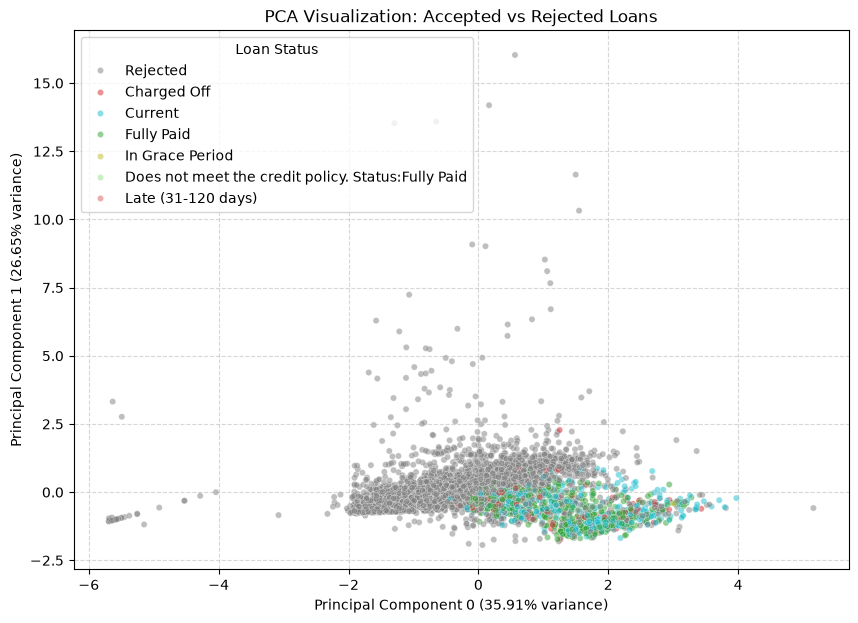

In [39]:
# 5. Visualization with custom colors for Accepted (Green) vs. Rejected (Red)
STATUS_PALETTE = {
    # good outcomes -> green
    "Fully Paid": "#2ca02c",
    "Does not meet the credit policy. Status:Fully Paid": "#98df8a",
    # neutral -> blue
    "Accepted": "#1f77b4",
    "Current": "#17becf",
    # no loan -> gray
    "Rejected": "#7f7f7f",
    # warnings -> yellow to orange
    "In Grace Period": "#bcbd22",
    "Late (16-30 days)": "#ff7f0e",
    "Late (31-120 days)": "#e15759",
    # bad outcomes -> red to dark red
    "Charged Off": "#d62728",
    "Does not meet the credit policy. Status:Charged Off": "#ff9896",
    "Default": "#7f0000",
}
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x="pca0",
    y="pca1",
    hue="loan_status",
    palette=STATUS_PALETTE,
    data=training_df.sample(5000).to_pandas(),#.query("loan_status != 'Rejected'"),
    alpha=0.5,
    s=20,
)

plt.title("PCA Visualization: Accepted vs Rejected Loans")
plt.xlabel(
    f"Principal Component 0 ({pca.explained_variance_ratio_[0]*100:.2f}% variance)"
)
plt.ylabel(
    f"Principal Component 1 ({pca.explained_variance_ratio_[1]*100:.2f}% variance)"
)
plt.legend(title="Loan Status")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## Finished ! The rest is fron the original notebook